In [1]:
# Statistical analysis for the CT Hospital Boarding manuscript.

# Self-contained reproduction of every quantitative result in the manuscript:
#   - Cohort filter
#   - Predictor definitions (bed utilization, Surgical Bed Demand, Nurse Staffing Ratio)
#   - Bivariate associations (Spearman + Pearson)
#   - Multivariable OLS with cluster-robust SE (n = 46 hospital-years)
#   - Variance inflation factors
#   - Hospital-averaged sensitivity (n = 23)
#   - Within-hospital change-score analysis (n = 23 paired)
#   - Bed utilization decomposition (sensitivity)

# Inputs:
#   - analytic_panel.csv  (one row per hospital × year, extracted from OHS Reports
#     400/450 plus the CT Boarding Workbook). 46 hospital-years after cohort filter.

# Initially Drafted By: Claude version ***

In [2]:
# Dependencies:
# matplotlib                3.11.0          py314haa95532_0
# numpy                     2.5.0           py314h650627e_0
# openpyxl                  3.1.5           py314h827c3e9_1
# pandas                    3.0.3           py314hf1216d0_0
# python                    3.14.6          hb107ab2_100_cp314
# scikit-learn              1.9.0           py314h9b39bef_0
# scipy                     1.18.0          py314h176032c_0
# seaborn                   0.13.2          py314haa95532_3

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, pearsonr, norm
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.regression.linear_model import OLS
import zipfile
import io
import os
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [4]:
boarding_data = pd.read_csv('./analysis_data/Raw Data/hospital_name_crosswalk.csv').join(pd.concat([
    pd.read_csv('./analysis_data/Raw Data/2024_boarding.csv'),
    pd.read_csv('./analysis_data/Raw Data/2025_boarding.csv')
]).set_index('hospital'), on='CCEP_name', how='left').set_index(['hospital_slug', 'year'])

In [5]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
report_450_values = []
report_400_values = []
for hospital_slug in boarding_data.index.get_level_values('hospital_slug').unique():
    additional_data = pd.read_excel(f'./analysis_data/Raw Data/450 reports/report450_{hospital_slug}_2025.xlsx')\
        .set_axis(['LINE', 'DESCRIPTION', 'ACTUAL FY2024', 'ACTUAL FY2025', 'AMOUNT DIFFERENCE', '% DIFFERENCE'], axis=1)\
        .set_index('DESCRIPTION')
    for year in [2024, 2025]:
        report_450_values.append({
            'hospital_slug': hospital_slug,
            'year': year,
            'inpatient_surgical_cases': additional_data.loc['Inpatient Surgical Procedures', f'ACTUAL FY{year}'],
            'outpatient_surgical_cases': additional_data.loc['Outpatient Surgical Procedures', f'ACTUAL FY{year}'],
            'total_nursing_hours': additional_data.loc['Total Nursing FTEs', f'ACTUAL FY{year}']
        })
    additional_data = pd.read_excel(f'./analysis_data/Raw Data/400 reports/report400_{hospital_slug}_2025.xlsx', skiprows=8).set_axis([
                'LINE','Bed Type',
                'Patient Days_2024','Patient Days_2025',
                'Discharges_2024','Discharges_2025',
                'Admissions_2024','Admissions_2025',
                'Staffed Beds_2024','Staffed Beds_2025',
                'Available Beds_2024','Available Beds_2025',
                '13', '14', '15', '16'
    ], axis=1).set_index('Bed Type')
    for year in [2024, 2025]:
        report_400_values.append({
            'hospital_slug': hospital_slug,
            'year': year,
            'patient_days_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Patient Days_{year}'],
            'admissions_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Admissions_{year}'],
            'staffed_beds_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Staffed Beds_{year}'],
            'available_beds_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Available Beds_{year}'],
            'total_inpatient_days': additional_data.loc[additional_data[f'Patient Days_{year}'] > 0, f'Patient Days_{year}'].sum(),
        })
main_data = boarding_data.join(pd.DataFrame(report_450_values).set_index(['hospital_slug', 'year']), how='left')\
    .join(pd.DataFrame(report_400_values).set_index(['hospital_slug', 'year']), how='left')

In [6]:
main_data.drop(['ct-children-s-medical-center'], axis=0, inplace=True) # exclude CT Childrens (Bristol already excluded from cohort filter)

In [7]:
main_data.to_csv('./analysis_data/Processed Data/analytic_panel.csv', index=True)

In [8]:
# ============================================================
# 3. PREDICTOR DEFINITIONS (three pre-specified operational dimensions)
# ============================================================
# Bed utilization: med/surg patient days ÷ (med/surg available beds × 365)
main_data['Bed Utilization'] = (main_data['patient_days_medical_surgical']
                  / (main_data['available_beds_medical_surgical'] * 365))

# Surgical Bed Demand: inpatient surgical procedures per med/surg staffed bed
main_data['Surgical Bed Demand'] = (main_data['inpatient_surgical_cases']
                  / main_data['available_beds_medical_surgical'])

# Nurse Staffing Ratio: nursing FTE per inpatient patient-day
main_data['Nurse Staffing Ratio'] = (main_data['total_nursing_hours'] * 365
                   / main_data['total_inpatient_days'])

# Bed utilization decomposition components (sensitivity analysis)
main_data['Staffed-Bed Proportion'] = (main_data['staffed_beds_medical_surgical']
                     / main_data['available_beds_medical_surgical'])
main_data['Staffed-Bed Occupancy'] = (main_data['patient_days_medical_surgical']
                     / (main_data['staffed_beds_medical_surgical'] * 365))



In [9]:
vars_for_table1 = {
    'patients_treated': 'ED Volume',
    'patients_admitted': 'ED Admissions',
    'avg_time_to_admit': 'Average ED Time to Admission (hours)',
    'boarding_percentage': 'Boarding Percentage',
    'Bed Utilization': 'Bed Utilization',
    'available_beds_medical_surgical': 'Available Med/Surg Beds',
    'patient_days_medical_surgical': 'Med/Surg Patient Days',
    'admissions_medical_surgical': 'Med/Surg Admissions',
    'staffed_beds_medical_surgical': 'Med/Surg Staffed Beds',
    'Surgical Bed Demand': 'Surgical Bed Demand',
    'inpatient_surgical_cases': 'Inpatient Surgical Cases',
    'outpatient_surgical_cases': 'Outpatient Surgical Cases',
    'Nurse Staffing Ratio': 'Nurse Staffing Ratio',
    'total_nursing_hours': 'Total Nursing Full-Time Equivalents',
    'total_inpatient_days': 'Total Inpatient Days',
    'Staffed-Bed Proportion': 'Staffed-Bed Proportion',
    'Staffed-Bed Occupancy': 'Staffed-Bed Occupancy',
}

table_1_data = main_data.reset_index().rename(columns=vars_for_table1)

def mean_ci_text(series):
    mean_val = series.mean()
    ci = norm.interval(0.95, loc=mean_val, scale=series.sem())
    return f"{mean_val:.2f} ({ci[0]:.2f}, {ci[1]:.2f})" if mean_val < 100 else f"{mean_val:.0f} ({ci[0]:.0f}, {ci[1]:.0f})"

def med_iqr_text(series):
    median_val = series.median()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    return f"{median_val:.2f} ({q1:.2f}, {q3:.2f})" if median_val < 100 else f"{median_val:.0f} ({q1:.0f}, {q3:.0f})"

rows = []
for label in vars_for_table1.values():
    row = {}
    for year in [2024, 2025]:
        row[f"{year} Statistics Mean (95% CI)"] = mean_ci_text(table_1_data.loc[table_1_data['year'] == year, label])
    ttest_result = stats.ttest_ind(
        table_1_data.loc[table_1_data['year'] == 2024, label].astype(float),
        table_1_data.loc[table_1_data['year'] == 2025, label].astype(float),
        equal_var=False, nan_policy='omit'
    )
    p_value = ttest_result.pvalue
    row['Two-Sided P-Value'] = "<0.01" if p_value < 0.01 else f"{p_value:.2f}"
    rows.append(row)
table1_by_year = pd.DataFrame(rows, index=vars_for_table1.values())
table1_by_year.to_csv('./analysis_data/Processed Data/table1_by_year.csv', index=True)
table1_by_year

,2024 Statistics Mean (95% CI),2025 Statistics Mean (95% CI),Two-Sided P-Value
ED Volume,"63230 (45737, 80723)","64444 (47267, 81621)",0.92
ED Admissions,"8777 (5550, 12005)","9319 (5825, 12814)",0.82
Average ED Time to Admission (hours),"324 (293, 355)","351 (315, 387)",0.28
Boarding Percentage,"33.59 (27.35, 39.83)","32.16 (26.23, 38.09)",0.75
Bed Utilization,"0.66 (0.59, 0.73)","0.66 (0.59, 0.73)",0.97
Available Med/Surg Beds,"191 (112, 270)","193 (115, 271)",0.97
Med/Surg Patient Days,"52426 (26918, 77935)","52725 (27506, 77945)",0.99
Med/Surg Admissions,"10917 (6671, 15163)","10902 (6659, 15145)",1.00
Med/Surg Staffed Beds,"166 (96, 236)","167 (96, 237)",0.99
Surgical Bed Demand,"14.16 (11.01, 17.32)","13.34 (10.58, 16.11)",0.70


In [55]:
rows=[]
for label in vars_for_table1.values():
    row = {}
    for year in [2024, 2025]:
        row[f"{year} Statistics Median (IQR)"] = med_iqr_text(table_1_data.loc[table_1_data['year'] == year, label])
    row["Association with Boarding Percentage Pearson r (Two-Sided P-Value)"] = '{:.2f} (p={:.4f})'.format(*pearsonr(table_1_data[label], table_1_data['Boarding Percentage'], alternative='two-sided'))
    rows.append(row)
table1_by_year = pd.DataFrame(rows, index=vars_for_table1.values())
table1_by_year.to_csv('./analysis_data/Processed Data/table1_med_IQR_by_year.csv', index=True)
table1_by_year

,2024 Statistics Median (IQR),2025 Statistics Median (IQR),Association with Boarding Percentage Pearson r (Two-Sided P-Value)
ED Volume,"56602 (36522, 80235)","54159 (35081, 84057)",0.35 (p=0.0136)
ED Admissions,"7090 (4963, 8185)","7158 (4588, 8534)",0.43 (p=0.0016)
Average ED Time to Admission (hours),"331 (282, 366)","340 (284, 404)",0.35 (p=0.0116)
Boarding Percentage,"30.00 (22.40, 46.70)","32.20 (23.90, 39.20)",1.00 (p=0.0000)
Bed Utilization,"0.70 (0.52, 0.80)","0.72 (0.55, 0.78)",0.39 (p=0.0053)
Available Med/Surg Beds,"139 (101, 188)","138 (101, 191)",0.38 (p=0.0060)
Med/Surg Patient Days,"37070 (19963, 52865)","37939 (18397, 52168)",0.40 (p=0.0037)
Med/Surg Admissions,"9157 (4991, 10402)","9109 (4807, 11115)",0.44 (p=0.0013)
Med/Surg Staffed Beds,"137 (63, 159)","130 (63, 162)",0.43 (p=0.0017)
Surgical Bed Demand,"13.56 (9.87, 17.79)","13.05 (9.28, 16.02)",0.57 (p=0.0000)


In [11]:
table_1_data.loc[:, vars_for_table1.values()].apply(med_iqr_text).rename("Statistics Median (IQR)").to_csv('./analysis_data/Processed Data/table1_med_iqr_overall.csv', index=True)

In [12]:
table_1_data.loc[:, vars_for_table1.values()].apply(mean_ci_text).rename("Statistics Mean (95% CI)").to_csv('./analysis_data/Processed Data/table1_overall.csv', index=True)

In [13]:
table_1_data.set_index(['CCEP_name', 'year'])[list(vars_for_table1.values())].sort_index().to_csv('./analysis_data/Processed Data/table1_raw.csv', index=True)

In [14]:
table_1_data.groupby('CCEP_name')[[
    'ED Volume',
    'ED Admissions',
    'Boarding Percentage',
    'Available Med/Surg Beds',
    'Med/Surg Staffed Beds',
    'Total Inpatient Days',
    'Inpatient Surgical Cases',
    'Total Nursing Full-Time Equivalents',
]].agg('mean').round(0).astype(int).to_csv('./analysis_data/Processed Data/table1_by_hospital.csv', index=True)

In [15]:
table1 = main_data.describe().map(lambda x: f"{x:,.2f}")
table1.to_csv('./analysis_data/Processed Data/table1.csv', index=True)

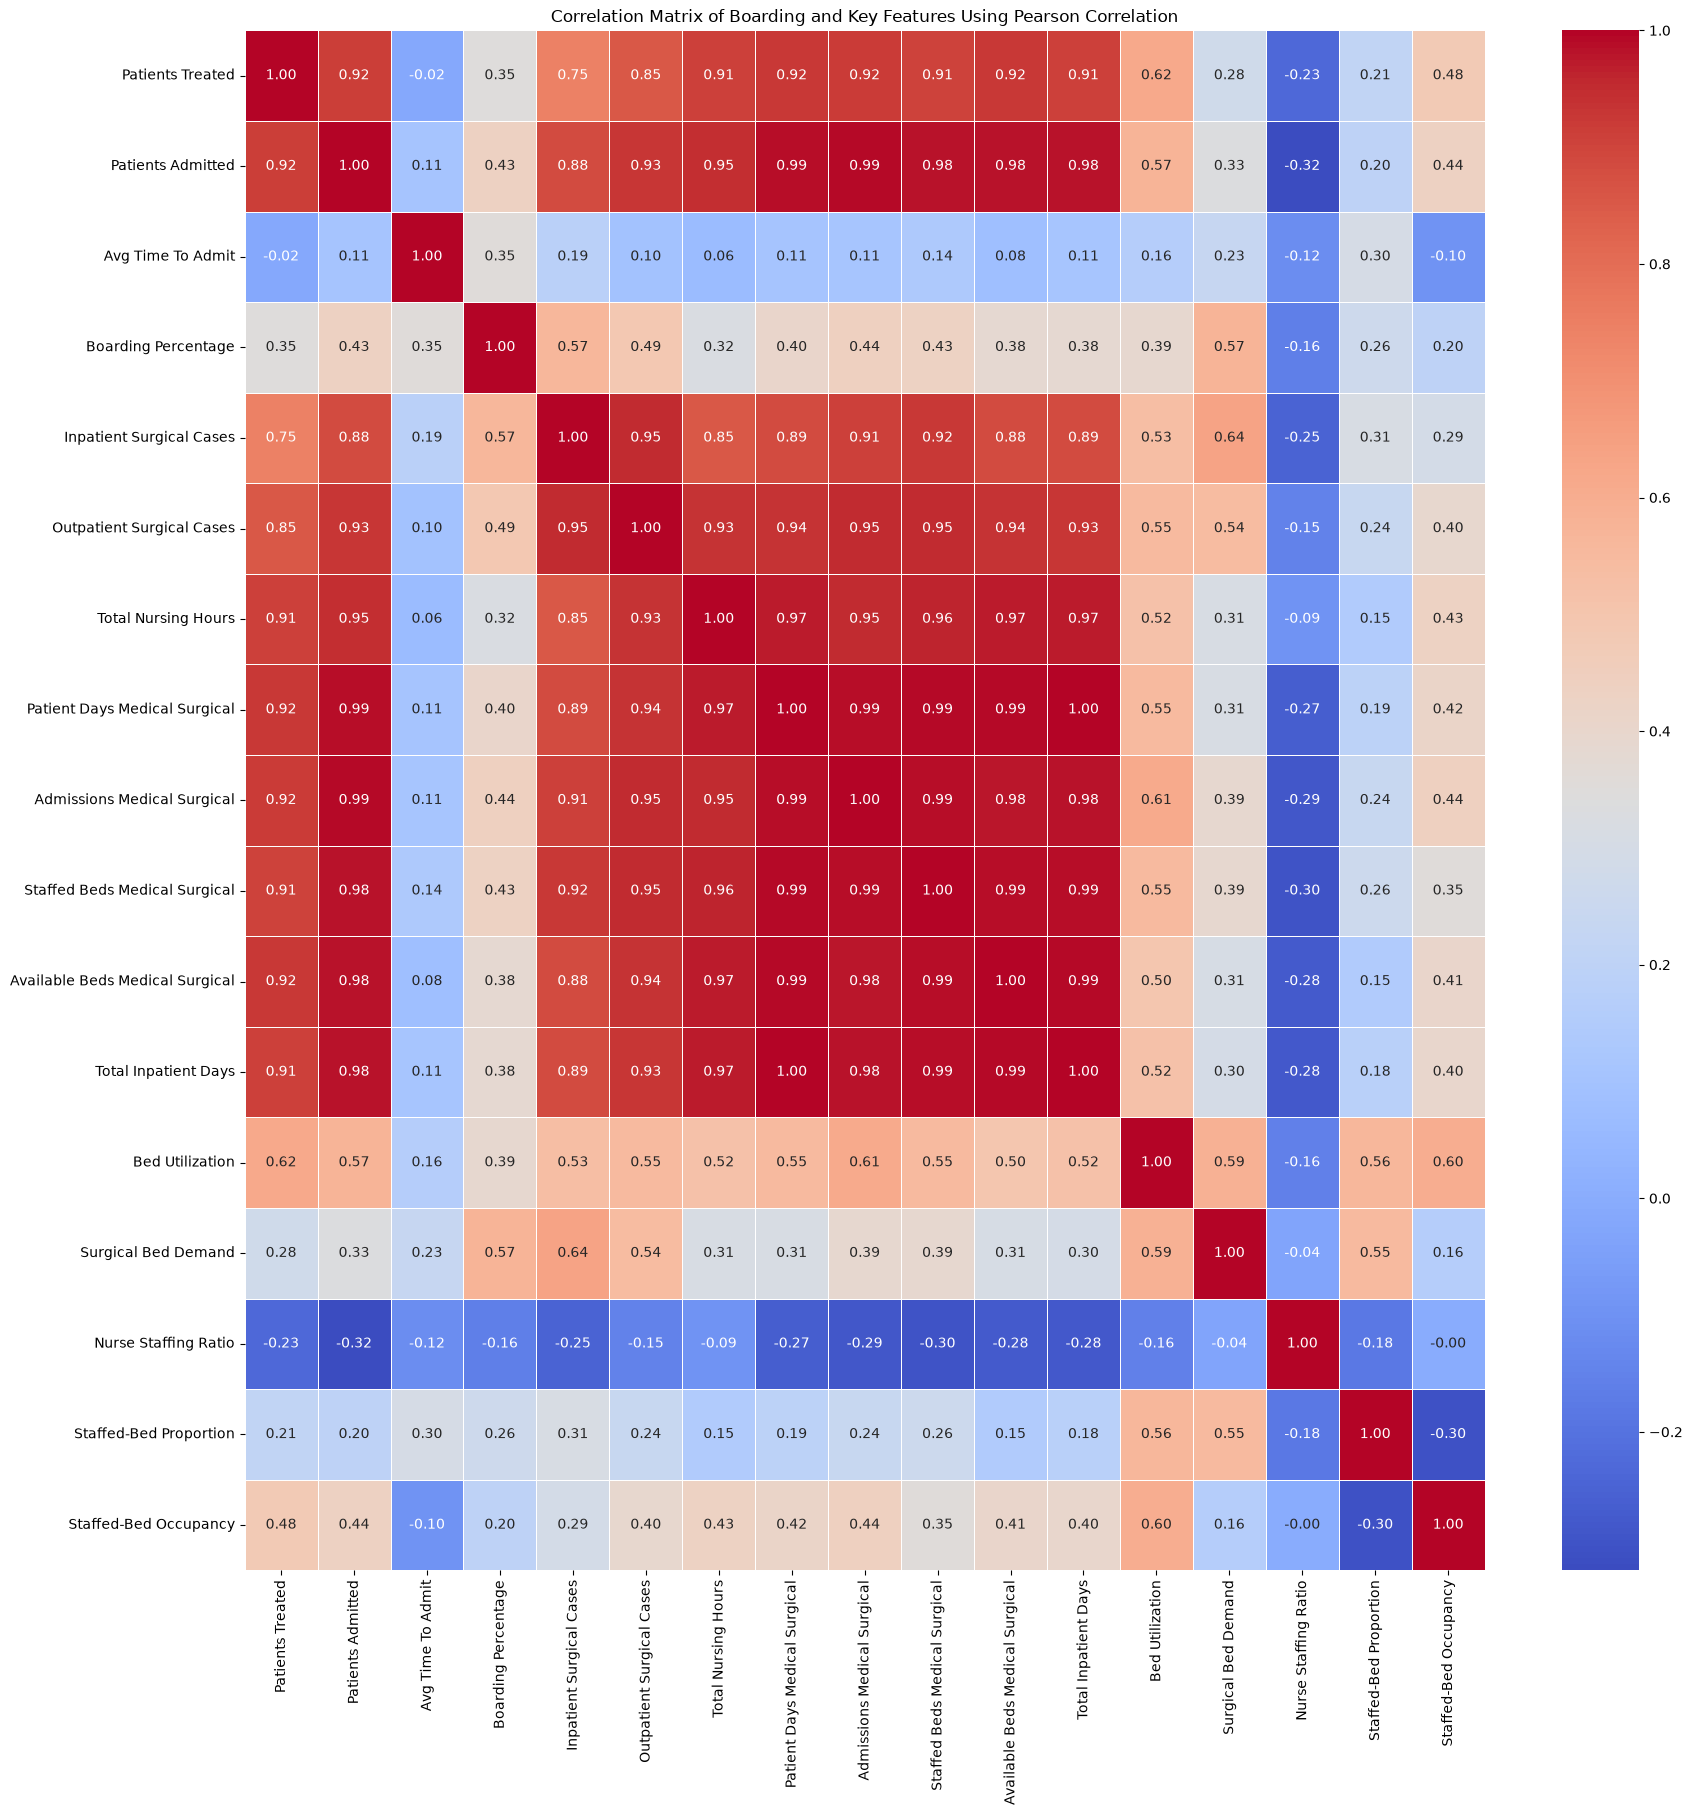

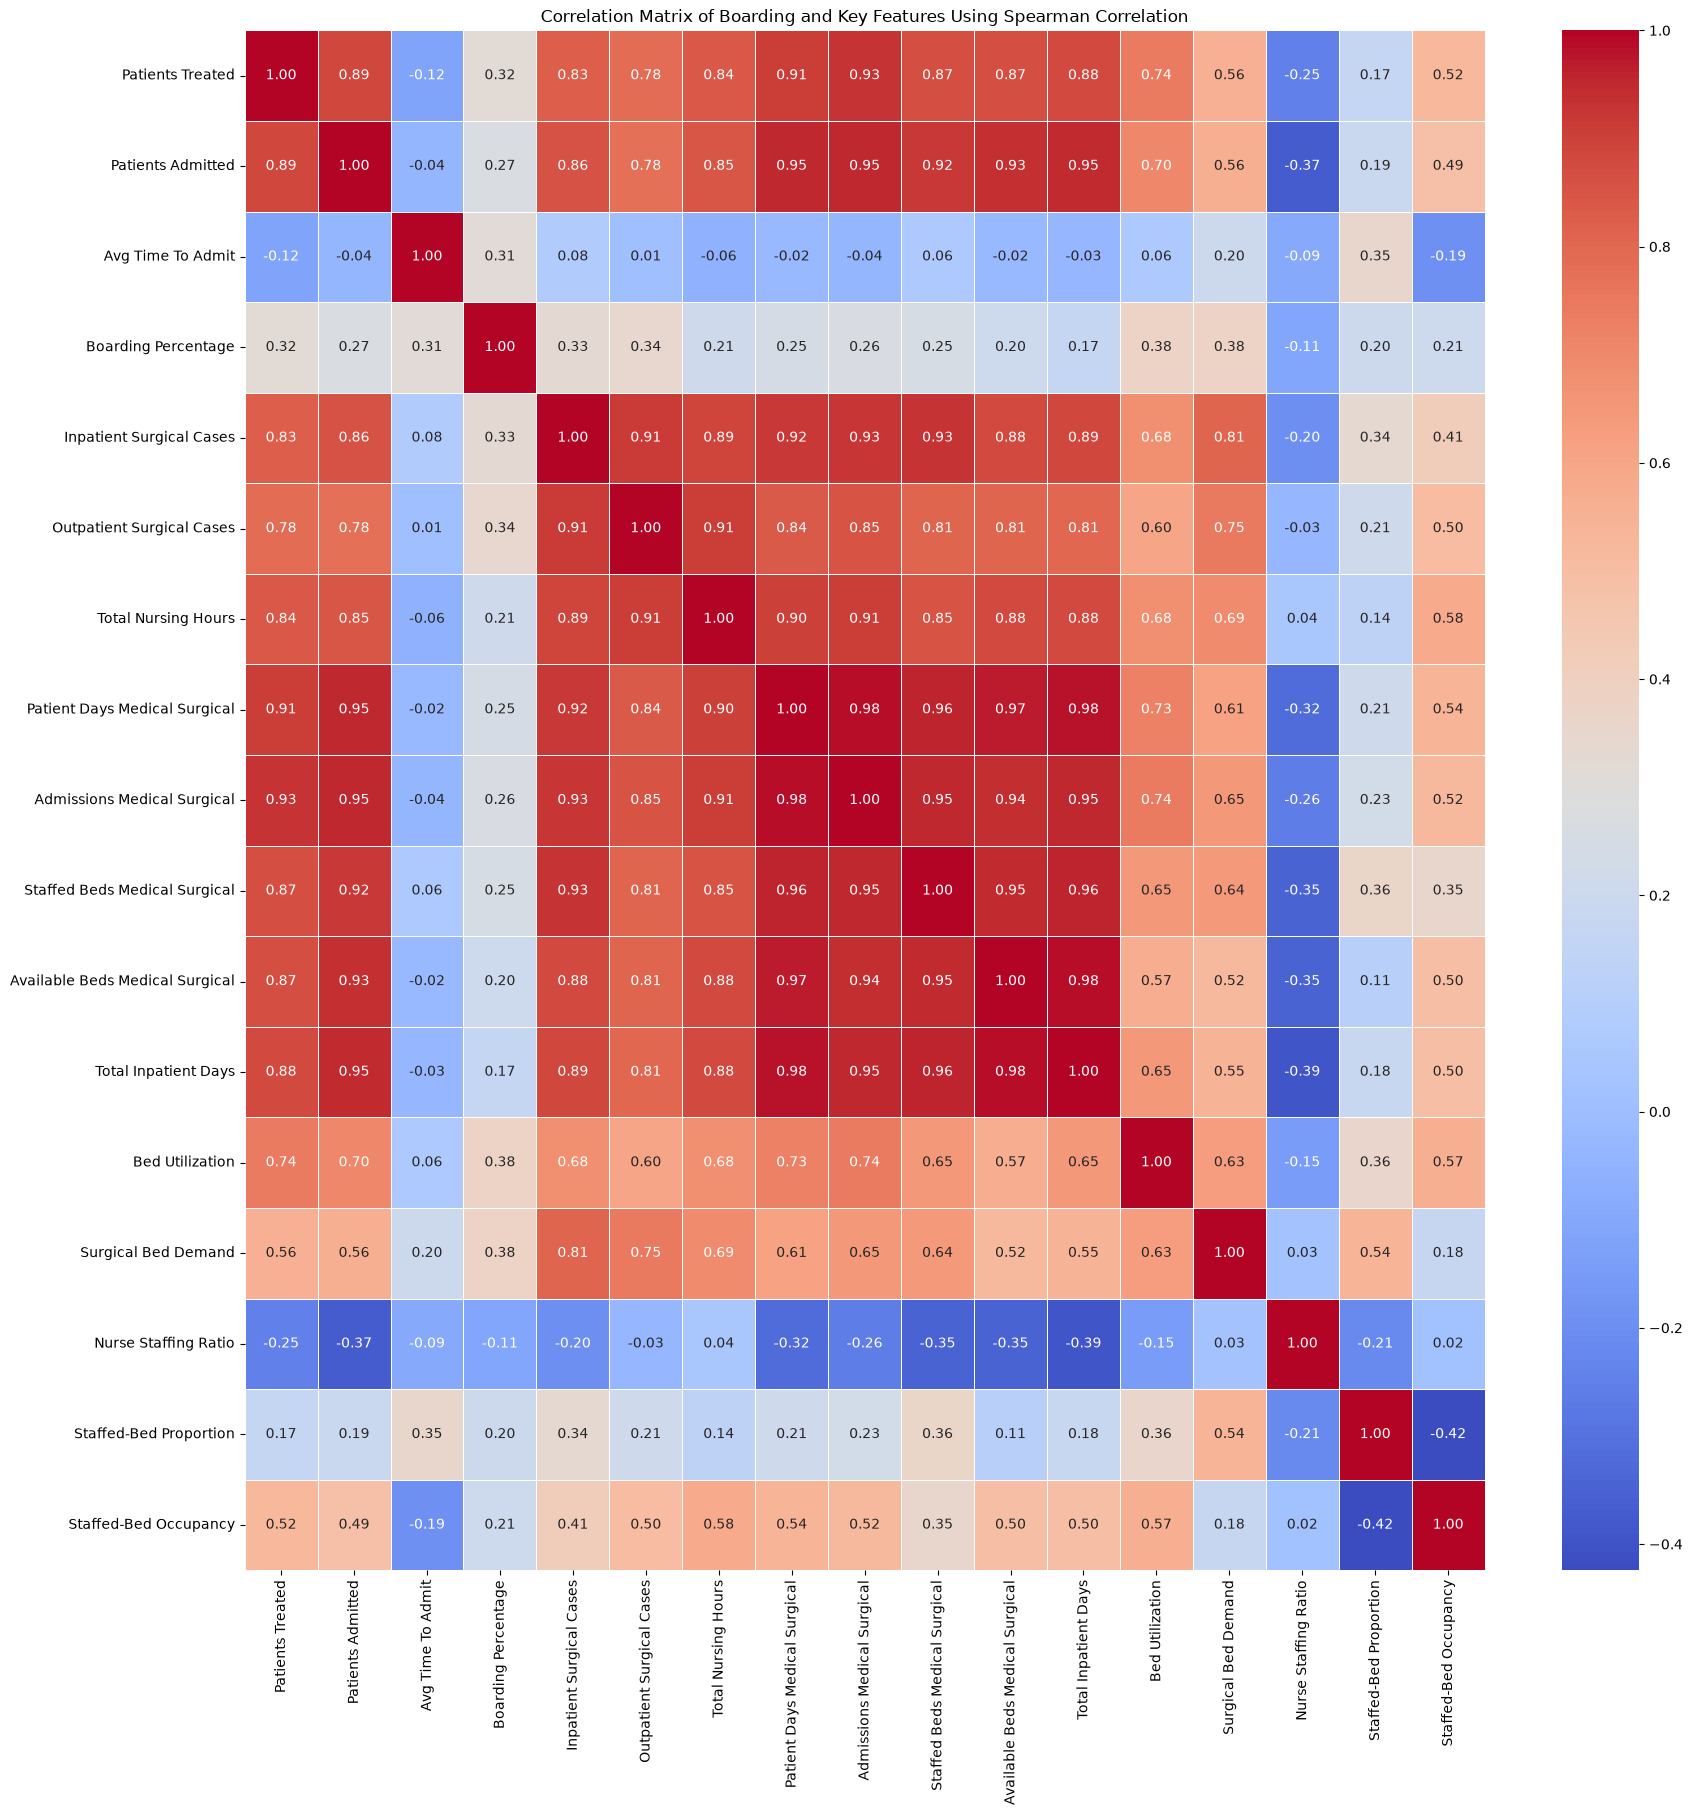

In [16]:
for correlation_method in ['pearson', 'spearman']:
    corr_matrix = main_data.iloc[:,1:].rename(columns=lambda x: x.replace('_', ' ').title()).corr(method=correlation_method)
    plt.figure(figsize=(20, 20))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title(f'Correlation Matrix of Boarding and Key Features Using {correlation_method.capitalize()} Correlation')
    plt.savefig(f'./analysis_data/Processed Data/correlation_heatmap_{correlation_method}.png', bbox_inches='tight')
    plt.show()

In [17]:
spearman_corr = main_data[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'Staffed-Bed Proportion', 'Staffed-Bed Occupancy']]\
    .agg(lambda x: 'spearman rho: {:.2f} (p={:.4f})'.format(*spearmanr(x, main_data['boarding_percentage'], alternative='two-sided')))
pearson_corr = main_data[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'Staffed-Bed Proportion', 'Staffed-Bed Occupancy']]\
    .agg(lambda x: 'pearson r: {:.2f} (p={:.4f})'.format(*pearsonr(x, main_data['boarding_percentage'], alternative='two-sided')))
(spearman_corr + " " + pearson_corr).to_csv('./analysis_data/Processed Data/bivariate_correlations.csv', index=True)

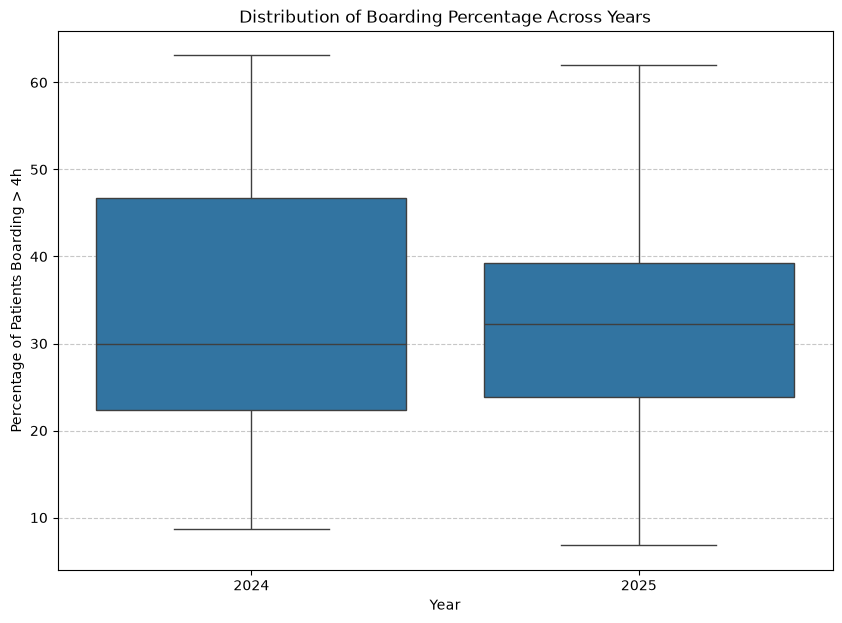

In [18]:
plt.figure(figsize=(10, 7))
sns.boxplot(x='year', y='boarding_percentage', data=main_data.reset_index())
plt.title('Distribution of Boarding Percentage Across Years')
plt.ylabel('Percentage of Patients Boarding > 4h')
plt.xlabel('Year')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('./analysis_data/Processed Data/boarding_year_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()


In [19]:
compare_years = main_data.reset_index()[['year', 'boarding_percentage']]
ttest = stats.ttest_ind(
    compare_years[compare_years['year'] == 2024]['boarding_percentage'],
    compare_years[compare_years['year'] == 2025]['boarding_percentage'],
    alternative='two-sided'
)
print(f"T-test result for boarding percentage between 2024 and 2025: t-statistic = {ttest.statistic:.4f}, p-value = {ttest.pvalue:.4f}")
compare_years.groupby('year').describe()

T-test result for boarding percentage between 2024 and 2025: t-statistic = 0.3261, p-value = 0.7457


boarding_percentage                                                
                   count    mean        std  min   25%   50%   75%   max
year                                                                    
2024                25.0  33.592  15.919797  8.7  22.4  30.0  46.7  63.1
2025                25.0  32.160  15.117677  6.8  23.9  32.2  39.2  62.0

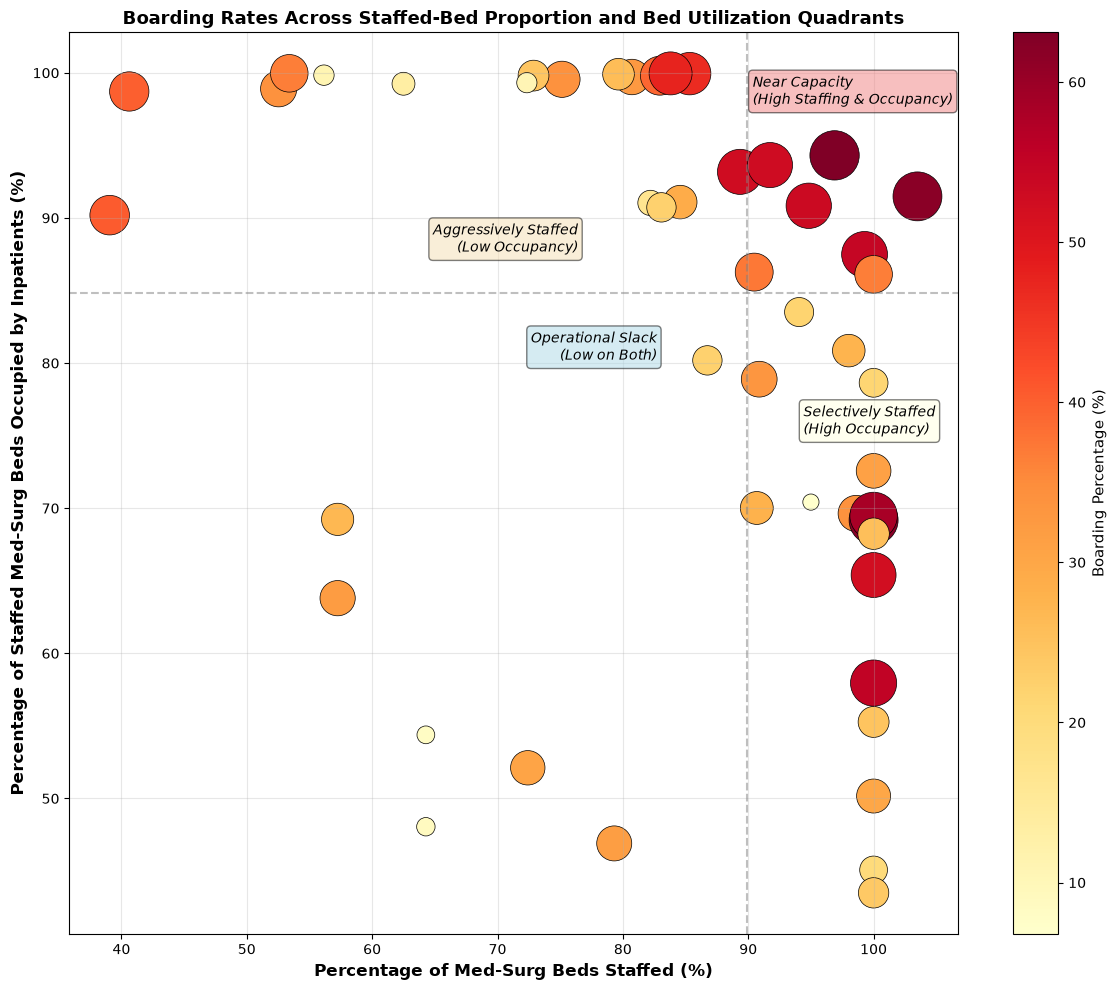

In [20]:
# Create scatter plot of staffed percentage vs occupancy with boarding percentage as point size
fig, ax = plt.subplots(figsize=(12, 10))
# Calculate medians for quadrant lines
med_x = main_data['Staffed-Bed Proportion'].median() * 100
med_y = main_data['Staffed-Bed Occupancy'].median() * 100
# Add dotted median lines
ax.axvline(med_x, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.axhline(med_y, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.grid(True, alpha=0.3)
# Scatter plot with boarding_percentage as size
scatter = ax.scatter(main_data['Staffed-Bed Proportion'] * 100, 
                     main_data['Staffed-Bed Occupancy'] * 100,
                     s=main_data['boarding_percentage'] * 20,  # scale for visibility
                     alpha=1, 
                     c=main_data['boarding_percentage'],
                     cmap='YlOrRd',
                     edgecolors='black',
                     linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Boarding Percentage (%)', fontsize=11)

# Add quadrant labels
ax.text(med_x * 0.85, med_y * 1.03, 'Aggressively Staffed\n(Low Occupancy)', 
        fontsize=10, ha='right', va='bottom', style='italic', 
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(med_x * 1.005, med_y * 1.15, 'Near Capacity\n(High Staffing & Occupancy)', 
        fontsize=10, ha='left', va='bottom', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.5))
ax.text(med_x * 0.92, med_y * 0.97, 'Operational Slack\n(Low on Both)', 
        fontsize=10, ha='right', va='top', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
ax.text(med_x * 1.05, med_y * 0.91, 'Selectively Staffed\n(High Occupancy)', 
        fontsize=10, ha='left', va='top', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

ax.set_xlabel('Percentage of Med-Surg Beds Staffed (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Percentage of Staffed Med-Surg Beds Occupied by Inpatients (%)', fontsize=12, fontweight='bold')
ax.set_title('Boarding Rates Across Staffed-Bed Proportion and Bed Utilization Quadrants', 
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('./analysis_data/Processed Data/staffing_occupancy_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

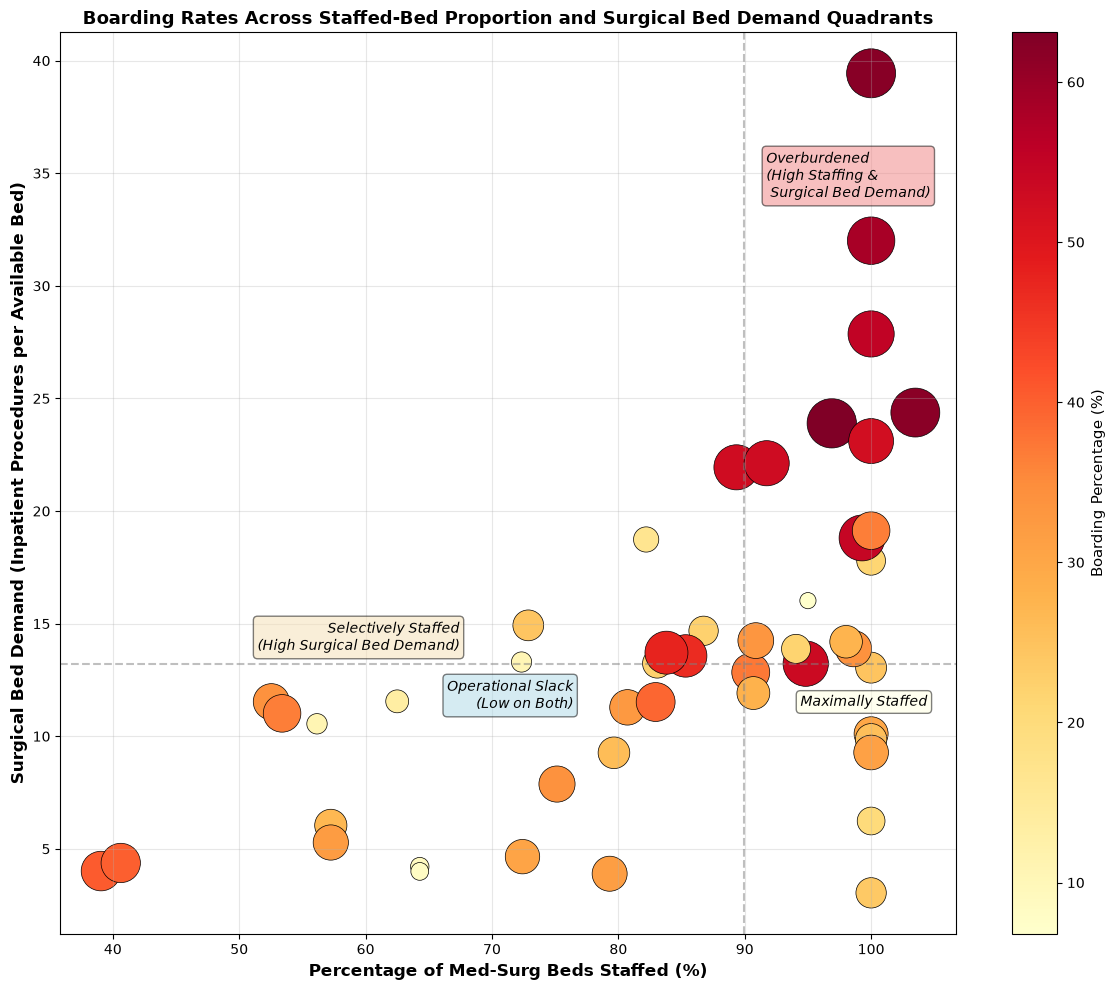

In [66]:
# Create scatter plot of staffed percentage vs occupancy with boarding percentage as point size
fig, ax = plt.subplots(figsize=(12, 10))
# Calculate medians for quadrant lines
med_x = main_data['Staffed-Bed Proportion'].median() * 100
med_y = main_data['Surgical Bed Demand'].median()
# Add dotted median lines
ax.axvline(med_x, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.axhline(med_y, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.grid(True, alpha=0.3)
# Scatter plot with boarding_percentage as size
scatter = ax.scatter(main_data['Staffed-Bed Proportion'] * 100, 
                     main_data['Surgical Bed Demand'],
                     s=main_data['boarding_percentage'] * 20,  # scale for visibility
                     alpha=1, 
                     c=main_data['boarding_percentage'],
                     cmap='YlOrRd',
                     edgecolors='black',
                     linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Boarding Percentage (%)', fontsize=11)

# Add quadrant labels
ax.text(med_x * 0.75, med_y * 1.03, 'Selectively Staffed\n(High Surgical Bed Demand)', 
        fontsize=10, ha='right', va='bottom', style='italic', 
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(med_x * 1.02, med_y * 2.55, 'Overburdened\n(High Staffing &\n Surgical Bed Demand)', 
        fontsize=10, ha='left', va='bottom', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.5))
ax.text(med_x * 0.85, med_y * 0.95, 'Operational Slack\n(Low on Both)', 
        fontsize=10, ha='right', va='top', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
ax.text(med_x * 1.05, med_y * 0.895, 'Maximally Staffed', 
        fontsize=10, ha='left', va='top', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

ax.set_xlabel('Percentage of Med-Surg Beds Staffed (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Surgical Bed Demand (Inpatient Procedures per Available Bed)', fontsize=12, fontweight='bold')
ax.set_title('Boarding Rates Across Staffed-Bed Proportion and Surgical Bed Demand Quadrants', 
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('./analysis_data/Processed Data/staffing_surgical_intensity_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
main_data['boarding_percentage'].describe()

count    50.000000
mean     32.876000
std      15.381709
min       6.800000
25%      22.775000
50%      31.500000
75%      40.475000
max      63.100000
Name: boarding_percentage, dtype: float64

In [58]:
main_data['Surgical Bed Demand'].describe()

count    50.000000
mean     13.752664
std       7.500721
min       3.047619
25%       9.426752
50%      13.230018
75%      17.349970
max      39.437700
Name: Surgical Bed Demand, dtype: float64

In [23]:
main_data[main_data['Staffed-Bed Proportion'] > 1]

,,CCEP_name,patients_treated,patients_admitted,avg_time_to_admit,boarding_percentage,inpatient_surgical_cases,outpatient_surgical_cases,total_nursing_hours,patient_days_medical_surgical,admissions_medical_surgical,staffed_beds_medical_surgical,available_beds_medical_surgical,total_inpatient_days,Bed Utilization,Surgical Bed Demand,Nurse Staffing Ratio,Staffed-Bed Proportion,Staffed-Bed Occupancy
hospital_slug,year,,,,,,,,,,,,,,,,,,
hartford-hospital,2025,Hartford Hospital,109166,28322,533.46,62.0,13235,26480,2117.05,187665.0,36845.0,562.0,543.0,293549.0,0.946871,24.373849,2.632348,1.034991,0.914859


In [59]:
output_dict = {}
filtered_data = main_data.loc[main_data['boarding_percentage'] >= 40]
output_dict["99% Occupancy"] = [
    filtered_data['Staffed-Bed Occupancy'].ge(0.99).sum() / filtered_data.shape[0],
    main_data['Staffed-Bed Occupancy'].ge(0.99).sum() / main_data.shape[0]
]
output_dict["99% Staffing"] = [
    filtered_data['Staffed-Bed Proportion'].ge(0.99).sum() / filtered_data.shape[0],
    main_data['Staffed-Bed Proportion'].ge(0.99).sum() / main_data.shape[0]
]
output_dict["High Surgical Bed Demand\n(17.3 Procedures per Available Bed)"] = [
    filtered_data['Surgical Bed Demand'].ge(17.3).sum() / filtered_data.shape[0],
    main_data['Surgical Bed Demand'].ge(17.3).sum() / main_data.shape[0]
]
output_dict["99% Staffing + High Surgical Bed Demand"] = [
    (filtered_data['Staffed-Bed Proportion'].ge(0.99) & filtered_data['Surgical Bed Demand'].ge(17.3)).sum() / filtered_data.shape[0],
    (main_data['Staffed-Bed Proportion'].ge(0.99) & main_data['Surgical Bed Demand'].ge(17.3)).sum() / main_data.shape[0]
]
boarding_ratios = pd.DataFrame(output_dict, index=['Boarding ≥ 40%', 'All Hospital-Years']).T
boarding_ratios_output = boarding_ratios.copy()
boarding_ratios_output['Boarding ≥ 40%'] = boarding_ratios_output['Boarding ≥ 40%'].apply(lambda x: f"{x*100:.1f} (N={int(x * filtered_data.shape[0])})")
boarding_ratios_output['All Hospital-Years'] = boarding_ratios_output['All Hospital-Years'].apply(lambda x: f"{x*100:.1f} (N={int(x * main_data.shape[0])})")
boarding_ratios_output.to_csv('./analysis_data/Processed Data/boarding_ratios.csv', index=True)

In [60]:
filtered_data["Above-Median Occupancy"] = filtered_data['Staffed-Bed Occupancy'].ge(main_data['Staffed-Bed Occupancy'].median())
filtered_data["Above-Median Staffing"] = filtered_data['Staffed-Bed Proportion'].ge(main_data['Staffed-Bed Proportion'].median())
filtered_data["High Surgical Bed Demand"] = filtered_data['Surgical Bed Demand'].ge(main_data['Surgical Bed Demand'].median())
filtered_data["Above-Median Staffing + High Surgical Bed Demand"] = filtered_data['Staffed-Bed Proportion'].ge(main_data['Staffed-Bed Proportion'].median()) & filtered_data['Surgical Bed Demand'].ge(main_data['Surgical Bed Demand'].median())
filtered_data[["Above-Median Occupancy", "Above-Median Staffing", "High Surgical Bed Demand", "Above-Median Staffing + High Surgical Bed Demand", 'boarding_percentage']].sort_values(by = 'boarding_percentage', ascending=False)

Above-Median Occupancy  \
hospital_slug                             year                           
hartford-hospital                         2024                    True   
saint-francis-hospital-and-medical-center 2024                   False   
hartford-hospital                         2025                    True   
saint-francis-hospital-and-medical-center 2025                   False   
saint-mary-s-hospital                     2024                   False   
william-w-backus-hospital                 2024                    True   
charlotte-hungerford-hospital             2024                    True   
midstate-medical-center                   2025                    True   
                                          2024                    True   
saint-mary-s-hospital                     2025                   False   
yale-new-haven-hospital                   2025                    True   
                                          2024                    True   
day-kimball-hospital                      2024                    True   
                                          2025                    True   

                                                Above-Median Staffing  \
hospital_slug                             year                          
hartford-hospital                         2024                   True   
saint-francis-hospital-and-medical-center 2024                   True   
hartford-hospital                         2025                   True   
saint-francis-hospital-and-medical-center 2025                   True   
saint-mary-s-hospital                     2024                   True   
william-w-backus-hospital                 2024                   True   
charlotte-hungerford-hospital             2024                   True   
midstate-medical-center                   2025                   True   
                                          2024                  False   
saint-mary-s-hospital                     2025                   True   
yale-new-haven-hospital                   2025                  False   
                                          2024                  False   
day-kimball-hospital                      2024                  False   
                                          2025                  False   

                                                High Surgical Bed Demand  \
hospital_slug                             year                             
hartford-hospital                         2024                      True   
saint-francis-hospital-and-medical-center 2024                      True   
hartford-hospital                         2025                      True   
saint-francis-hospital-and-medical-center 2025                      True   
saint-mary-s-hospital                     2024                      True   
william-w-backus-hospital                 2024                      True   
charlotte-hungerford-hospital             2024                     False   
midstate-medical-center                   2025                      True   
                                          2024                      True   
saint-mary-s-hospital                     2025                      True   
yale-new-haven-hospital                   2025                      True   
                                          2024                      True   
day-kimball-hospital                      2024                     False   
                                          2025                     False   

                                                Above-Median Staffing + High Surgical Bed Demand  \
hospital_slug                             year                                                     
hartford-hospital                         2024                                              True   
saint-francis-hospital-and-medical-center 2024                                              True   
hartford-hospital                         2025                               

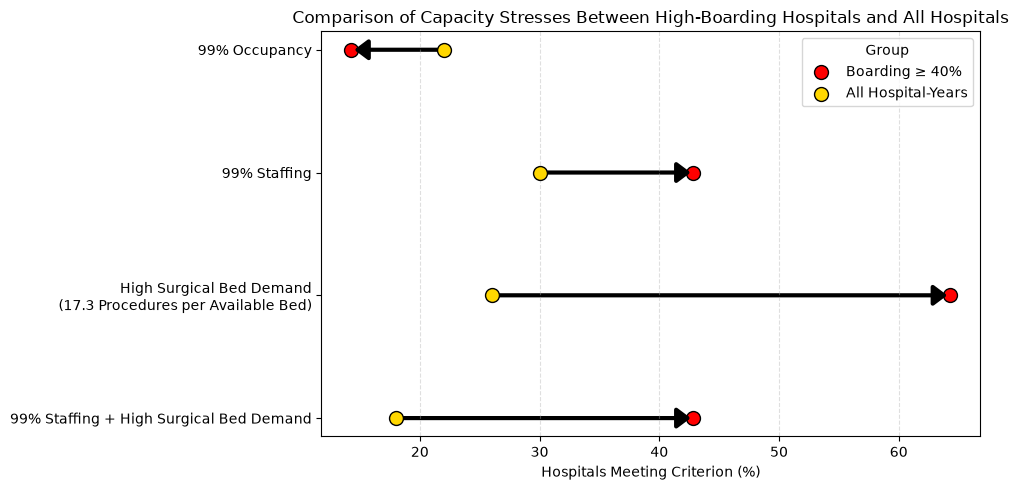

In [61]:
fig, ax = plt.subplots(figsize=(10, 5))

labels = boarding_ratios.index.astype(str)
high_boarders, all_hospitals = boarding_ratios.columns
x_a = boarding_ratios[high_boarders].to_numpy(dtype=float) * 100
x_b = boarding_ratios[all_hospitals].to_numpy(dtype=float) * 100
y = np.arange(len(labels))


ax.scatter(x_a, y, color='red', s=100, label=high_boarders, zorder=1, edgecolors='black', linewidth=1)
ax.scatter(x_b, y, color='gold', s=100, label=all_hospitals, zorder=2, edgecolors='black', linewidth=1)

# Draw arrows first so the points appear on top.
for yi, xa, xb in zip(y, x_a, x_b):
    ax.annotate(
        '',
        xy=(xb, yi),
        xytext=(xa, yi),
        arrowprops=dict(
            arrowstyle='<|-,head_width=0.6,head_length=0.8',
            color='black',
            lw=3,
        ),
        zorder=1,
    )


ax.set_yticks(y, labels)
ax.set_xlabel('Hospitals Meeting Criterion (%)')
ax.set_title('Comparison of Capacity Stresses Between High-Boarding Hospitals and All Hospitals')
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.legend(title='Group')
ax.invert_yaxis()
fig.tight_layout()
plt.savefig('./analysis_data/Processed Data/boarding_ratios_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

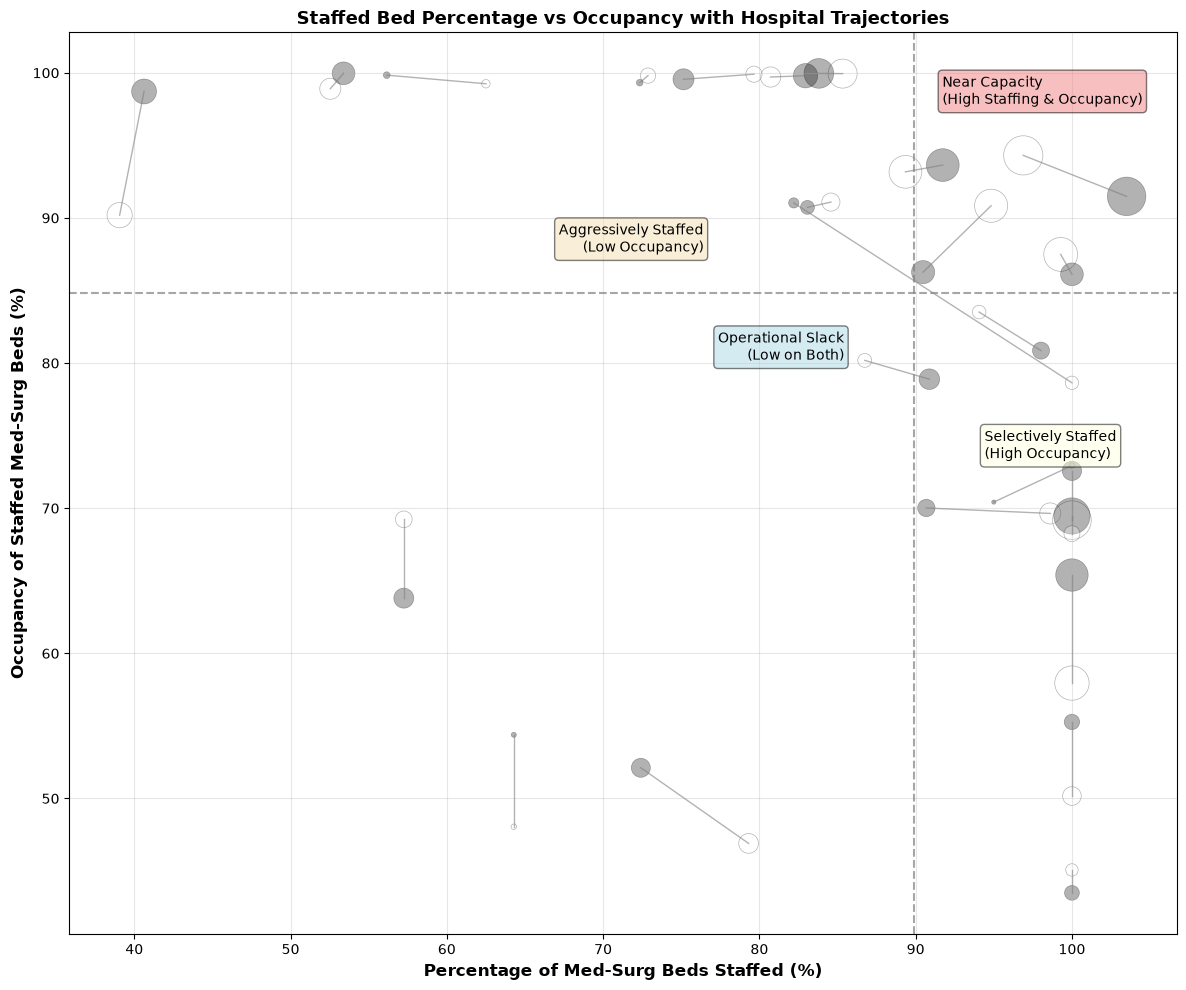

In [27]:
fig, ax = plt.subplots(figsize=(12, 10))

# Plot lines connecting the two years for each hospital
for hospital_slug, grp in main_data.reset_index().groupby('hospital_slug'):
    if len(grp) > 1:
        grp = grp.sort_values('year')
        ax.plot(grp['Staffed-Bed Proportion'] * 100,
                grp['Staffed-Bed Occupancy'] * 100,
                color='gray',
                linestyle='-',
                linewidth=1,
                alpha=0.6)

# Marker size approximating diameter from boarding percentage
sizes = (main_data['boarding_percentage'] ** 2) / 5

scatter = ax.scatter(main_data['Staffed-Bed Proportion'] * 100,
                     main_data['Staffed-Bed Occupancy'] * 100,
                     s=sizes,
                     c=main_data.reset_index()['year'],
                     cmap='binary',
                     alpha=0.3,
                     edgecolors='black',
                     linewidths=0.5)

med_x = main_data['Staffed-Bed Proportion'].median() * 100
med_y = main_data['Staffed-Bed Occupancy'].median() * 100

ax.axvline(med_x, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
ax.axhline(med_y, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

ax.text(med_x * 0.85, med_y * 1.03, 'Aggressively Staffed\n(Low Occupancy)',
        fontsize=10, ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(med_x * 1.02, med_y * 1.15, 'Near Capacity\n(High Staffing & Occupancy)',
        fontsize=10, ha='left', va='bottom',
        bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.5))
ax.text(med_x * 0.95, med_y * 0.97, 'Operational Slack\n(Low on Both)',
        fontsize=10, ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
ax.text(med_x * 1.05, med_y * 0.89, 'Selectively Staffed\n(High Occupancy)',
        fontsize=10, ha='left', va='top',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

ax.set_xlabel('Percentage of Med-Surg Beds Staffed (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Occupancy of Staffed Med-Surg Beds (%)', fontsize=12, fontweight='bold')
ax.set_title('Staffed Bed Percentage vs Occupancy with Hospital Trajectories', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./analysis_data/Processed Data/staffed_pct_vs_occupancy_trajectory_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

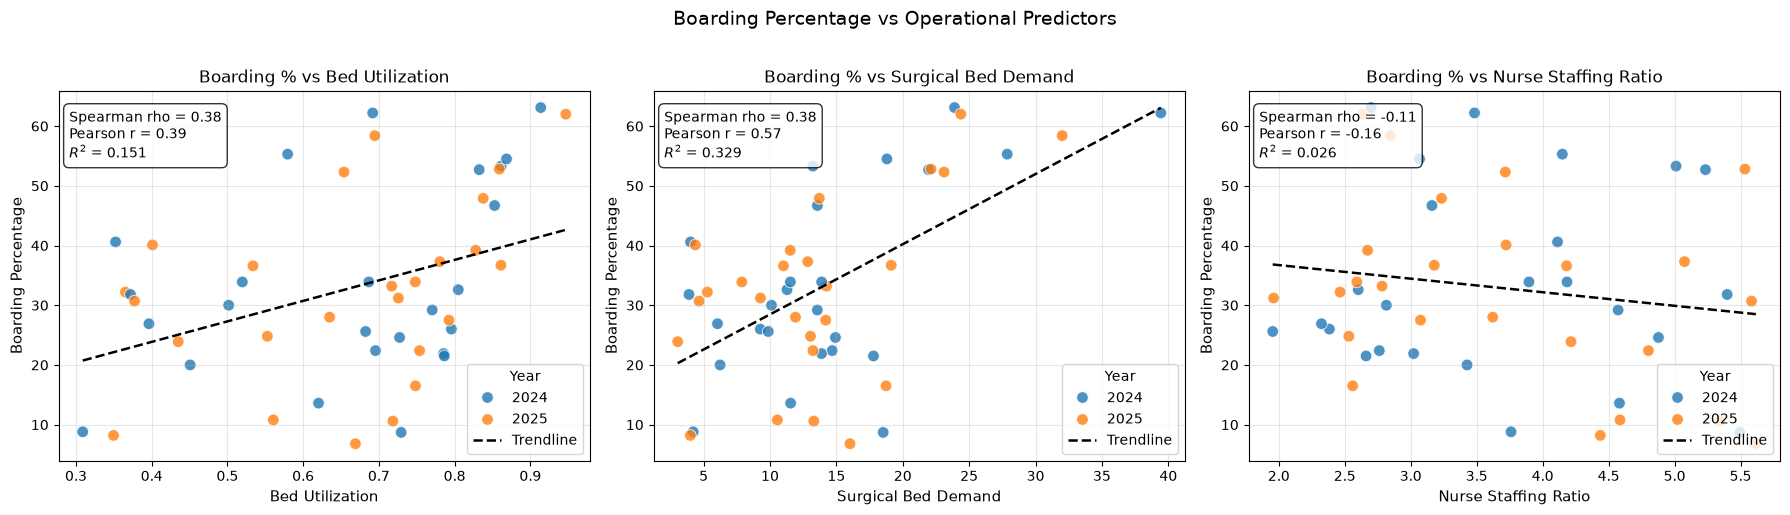

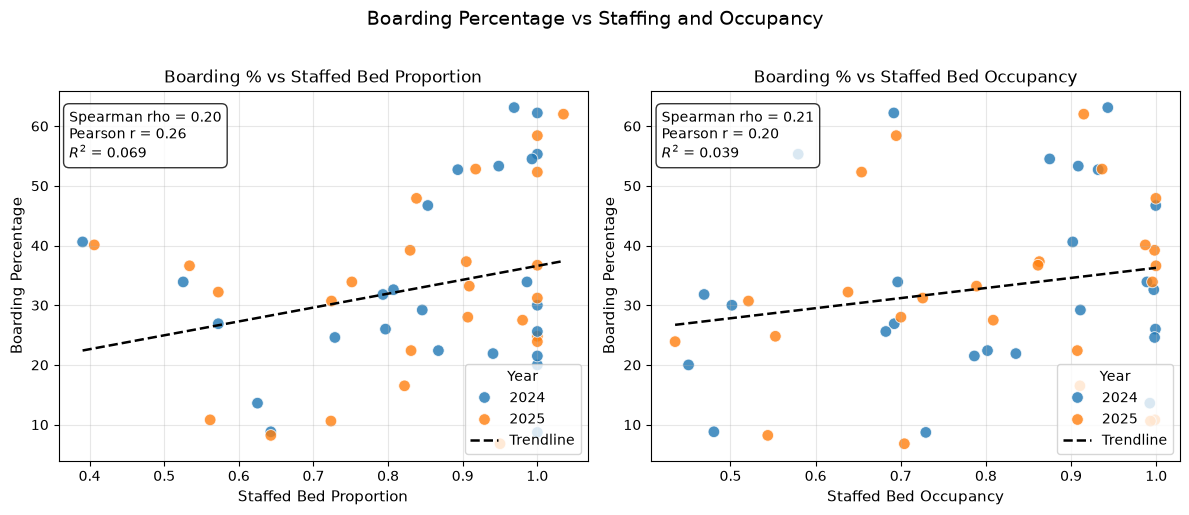

In [28]:
data = main_data.reset_index()

def plot_bivariate_scatter(vars_to_plot, fig_title, fig_path):
    fig, axes = plt.subplots(1, len(vars_to_plot), figsize=(6 * len(vars_to_plot), 5), sharey=False)
    if len(vars_to_plot) == 1:
        axes = [axes]

    for ax, (var_name, display_name) in zip(axes, vars_to_plot):
        subset = data[[var_name, 'boarding_percentage', 'year']].dropna()
        x = subset[var_name].astype(float)
        y = subset['boarding_percentage'].astype(float)

        # regression/trendline on full data
        lr = stats.linregress(x, y)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = lr.intercept + lr.slope * x_line

        sns.scatterplot(
            data=subset,
            x=var_name,
            y='boarding_percentage',
            hue='year',
            palette='tab10',
            alpha=0.8,
            s=70,
            ax=ax
        )
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=1.8, label='Trendline')

        rho, p_s = spearmanr(x, y)
        r, p_p = pearsonr(x, y)
        r2 = lr.rvalue ** 2
        p_linreg = lr.pvalue

        stats_text = (
            f"Spearman rho = {rho:.2f}\n"
            f"Pearson r = {r:.2f}\n"
            f"$R^2$ = {r2:.3f}"
        )

        ax.text(
            0.02, 0.95, stats_text,
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8)
        )

        ax.set_xlabel(display_name, fontsize=11)
        ax.set_ylabel('Boarding Percentage', fontsize=11)
        ax.set_title(f'Boarding % vs {display_name}', fontsize=12)
        ax.legend(title='Year', loc='lower right')
        ax.grid(alpha=0.3)

    fig.suptitle(fig_title, fontsize=14, y=1.02)
    fig.tight_layout()
    fig.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_bivariate_scatter(
    [
        ('Bed Utilization', 'Bed Utilization'),
        ('Surgical Bed Demand', 'Surgical Bed Demand'),
        ('Nurse Staffing Ratio', 'Nurse Staffing Ratio')
    ],
    'Boarding Percentage vs Operational Predictors',
    './analysis_data/Processed Data/boarding_vs_operational_predictors.png'
)

plot_bivariate_scatter(
    [
        ('Staffed-Bed Proportion', 'Staffed Bed Proportion'),
        ('Staffed-Bed Occupancy', 'Staffed Bed Occupancy')
    ],
    'Boarding Percentage vs Staffing and Occupancy',
    './analysis_data/Processed Data/boarding_vs_staffing_occupancy.png'
)

In [29]:
scaler = MinMaxScaler()
modeling_data = main_data.reset_index().set_index('CCEP_name')[['boarding_percentage', 'Staffed-Bed Proportion', 'Staffed-Bed Occupancy', 'Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'total_nursing_hours', 'patient_days_medical_surgical', 'available_beds_medical_surgical','inpatient_surgical_cases','year']]
modeling_data_scaled = modeling_data.copy()
modeling_data_scaled[modeling_data.columns] = scaler.fit_transform(modeling_data)

In [30]:
def unscale_data(coef_table,scaler_obj, requires_unscaling):
  ret_dict = {}
  for var in coef_table.index:
    coef = coef_table.loc[var, 'Coef.']
    se = coef_table.loc[var, 'Std.Err.']
    p_value = coef_table.loc[var, 'P>|z|']
    if requires_unscaling:
      scale = scaler_obj.scale_[np.where(scaler_obj.feature_names_in_ == var)[0][0]]
      coef_unscaled = coef * scale
      if np.abs(coef_unscaled) < 0.0001:
        coef_unscaled = coef_unscaled*1000
        se_unscaled = se * scale
        lower_unscaled = coef_unscaled - 1.96 * se_unscaled*1000
        upper_unscaled = coef_unscaled + 1.96 * se_unscaled*1000
        var = var + " (scaled x1000)"
      else:
        se_unscaled = se * scale
        lower_unscaled = coef_unscaled - 1.96 * se_unscaled
        upper_unscaled = coef_unscaled + 1.96 * se_unscaled
      ret_dict[var] = {
          'coef': f"{coef_unscaled:.4f}",
          '95% CI': f"({lower_unscaled:.4f} - {upper_unscaled:.4f})",
          'p_value': "0.0001" if p_value < 0.0001 else f"{p_value:.4f}"
      }
    else:
      ret_dict[var] = {
          'coef': f"{coef:.4f}",
          '95% CI': f"({(coef - 1.96 * se):.4f} - {(coef + 1.96 * se):.4f})",
          'p_value': "0.0001" if p_value < 0.0001 else f"{p_value:.4f}"
      }
  return pd.DataFrame(ret_dict).T

def run_OLS(endog, exog, requires_unscaling = True):
  exog = sm.add_constant(exog) # Add a constant to the exogenous variables
  ols_results = OLS(endog, exog).fit(cov_type='cluster', cov_kwds={'groups': endog.index})
  return pd.Series({
    'Coefficients': unscale_data(ols_results.summary2().tables[1].iloc[1:], scaler, requires_unscaling),
    'Condition Number': f"{ols_results.condition_number:.2f}",
    'R-squared': f"{ols_results.rsquared:.4f}",
    'BIC': f"{ols_results.bic:.2f}",
    'Log-Likelihood Function': ols_results.llf
  })

In [31]:
print("Running OLS regression: boarding percentage vs Staffed-Bed Proportion, Staffed-Bed Occupancy, Surgical Bed Demand, and Nurse Staffing Ratio...")
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Staffed-Bed Proportion', 'Staffed-Bed Occupancy', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'year']]).iloc[1:]

Running OLS regression: boarding percentage vs Staffed-Bed Proportion, Staffed-Bed Occupancy, Surgical Bed Demand, and Nurse Staffing Ratio...


Condition Number              13.65
R-squared                    0.3618
BIC                           12.15
Log-Likelihood Function    5.661428
dtype: object

In [32]:
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Staffed-Bed Proportion', 'Staffed-Bed Occupancy', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'year']]).iloc[0]

,coef,95% CI,p_value
Staffed-Bed Proportion,-0.0968,(-0.7272 - 0.5337),0.7635
Staffed-Bed Occupancy,0.1264,(-0.3384 - 0.5912),0.5939
Surgical Bed Demand,0.0214,(0.0125 - 0.0303),0.0001
Nurse Staffing Ratio,-0.0379,(-0.1389 - 0.0632),0.4628
year,-0.0087,(-0.0673 - 0.0498),0.7699


In [33]:
print("Running OLS regression: boarding percentage vs Bed Utilization, Surgical Bed Demand, and Nurse Staffing Ratio...")
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'year']]).iloc[1:]

Running OLS regression: boarding percentage vs Bed Utilization, Surgical Bed Demand, and Nurse Staffing Ratio...


Condition Number              9.63
R-squared                   0.3504
BIC                           9.12
Log-Likelihood Function    5.21815
dtype: object

In [34]:
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'year']]).iloc[0]

,coef,95% CI,p_value
Bed Utilization,0.0852,(-0.4446 - 0.6150),0.7525
Surgical Bed Demand,0.0195,(0.0111 - 0.0279),0.0001
Nurse Staffing Ratio,-0.0334,(-0.1299 - 0.0631),0.4974
year,-0.0076,(-0.0642 - 0.0490),0.7928


In [35]:
print("Running sensitivity test including volume metrics")
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['total_nursing_hours', 'patient_days_medical_surgical', 'available_beds_medical_surgical','inpatient_surgical_cases','year']]).iloc[1:]

Running sensitivity test including volume metrics


Condition Number              74.70
R-squared                    0.4506
BIC                            4.66
Log-Likelihood Function    9.405298
dtype: object

In [36]:
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['total_nursing_hours', 'patient_days_medical_surgical', 'available_beds_medical_surgical','inpatient_surgical_cases','Staffed-Bed Proportion','year']]).iloc[0]

,coef,95% CI,p_value
total_nursing_hours,-0.0003,(-0.0007 - 0.0000),0.0787
patient_days_medical_surgical (scaled x1000),0.0076,(-0.0034 - 0.0187),0.1763
available_beds_medical_surgical,-0.0017,(-0.0055 - 0.0021),0.3812
inpatient_surgical_cases (scaled x1000),0.0708,(0.0482 - 0.0934),0.0001
Staffed-Bed Proportion,-0.0786,(-0.6735 - 0.5164),0.7957
year,-0.0146,(-0.0670 - 0.0377),0.5839


In [37]:
print("Runs for R-squared for individual predictors:")
for predictor in ['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio']:
    print(f"Predictor: {predictor}")
    print(run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[[predictor]]).iloc[2])

Runs for R-squared for individual predictors:
Predictor: Bed Utilization
0.1512
Predictor: Surgical Bed Demand
0.3286
Predictor: Nurse Staffing Ratio
0.0258


In [38]:
# ============================================================
# 7. VARIANCE INFLATION FACTORS
# ============================================================
print('\n' + '=' * 72)
print('VARIANCE INFLATION FACTORS (pooled n = 48)')
print('=' * 72)
X_with_const = sm.add_constant(modeling_data_scaled[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio']])  # Add a constant to the exogenous variables
for i, p in enumerate(['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio']):
    vif = variance_inflation_factor(X_with_const.values, i + 1)
    print(f'  VIF({p:<12s}) = {vif:.2f}')
print('\n' + '=' * 72)
print('VARIANCE INFLATION FACTORS SENSITIVITY ANALYSIS(pooled n = 48)')
print('=' * 72)
X_with_const = sm.add_constant(modeling_data_scaled[['Staffed-Bed Proportion', 'Staffed-Bed Occupancy', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'year']])  # Add a constant to the exogenous variables
for i, p in enumerate(['Staffed-Bed Proportion', 'Staffed-Bed Occupancy', 'Surgical Bed Demand', 'Nurse Staffing Ratio', 'year']):
    vif = variance_inflation_factor(X_with_const.values, i + 1)
    print(f'  VIF({p:<12s}) = {vif:.2f}')



VARIANCE INFLATION FACTORS (pooled n = 48)
  VIF(Bed Utilization) = 1.57
  VIF(Surgical Bed Demand) = 1.53
  VIF(Nurse Staffing Ratio) = 1.03

VARIANCE INFLATION FACTORS SENSITIVITY ANALYSIS(pooled n = 48)
  VIF(Staffed-Bed Proportion) = 1.94
  VIF(Staffed-Bed Occupancy) = 1.34
  VIF(Surgical Bed Demand) = 1.75
  VIF(Nurse Staffing Ratio) = 1.05
  VIF(year        ) = 1.01


In [39]:
hospital_averaged_sensitivity_analysis = main_data.groupby('hospital_slug')[['boarding_percentage', 'Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio']].mean()
hospital_averaged_sensitivity_analysis_scaled = pd.DataFrame(scaler.fit_transform(hospital_averaged_sensitivity_analysis), columns=hospital_averaged_sensitivity_analysis.columns, index=hospital_averaged_sensitivity_analysis.index)
run_OLS(hospital_averaged_sensitivity_analysis_scaled['boarding_percentage'], hospital_averaged_sensitivity_analysis_scaled[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio']], requires_unscaling=True).iloc[1:]

Condition Number               8.17
R-squared                    0.3738
BIC                            6.67
Log-Likelihood Function    3.100728
dtype: object

In [40]:
run_OLS(hospital_averaged_sensitivity_analysis_scaled['boarding_percentage'], hospital_averaged_sensitivity_analysis_scaled[['Bed Utilization', 'Surgical Bed Demand', 'Nurse Staffing Ratio']], requires_unscaling=True).iloc[0]

,coef,95% CI,p_value
Bed Utilization,0.0594,(-0.4967 - 0.6156),0.8341
Surgical Bed Demand,0.0208,(0.0121 - 0.0295),0.0001
Nurse Staffing Ratio,-0.0357,(-0.1386 - 0.0672),0.4967


### Additional Descriptive Analysis

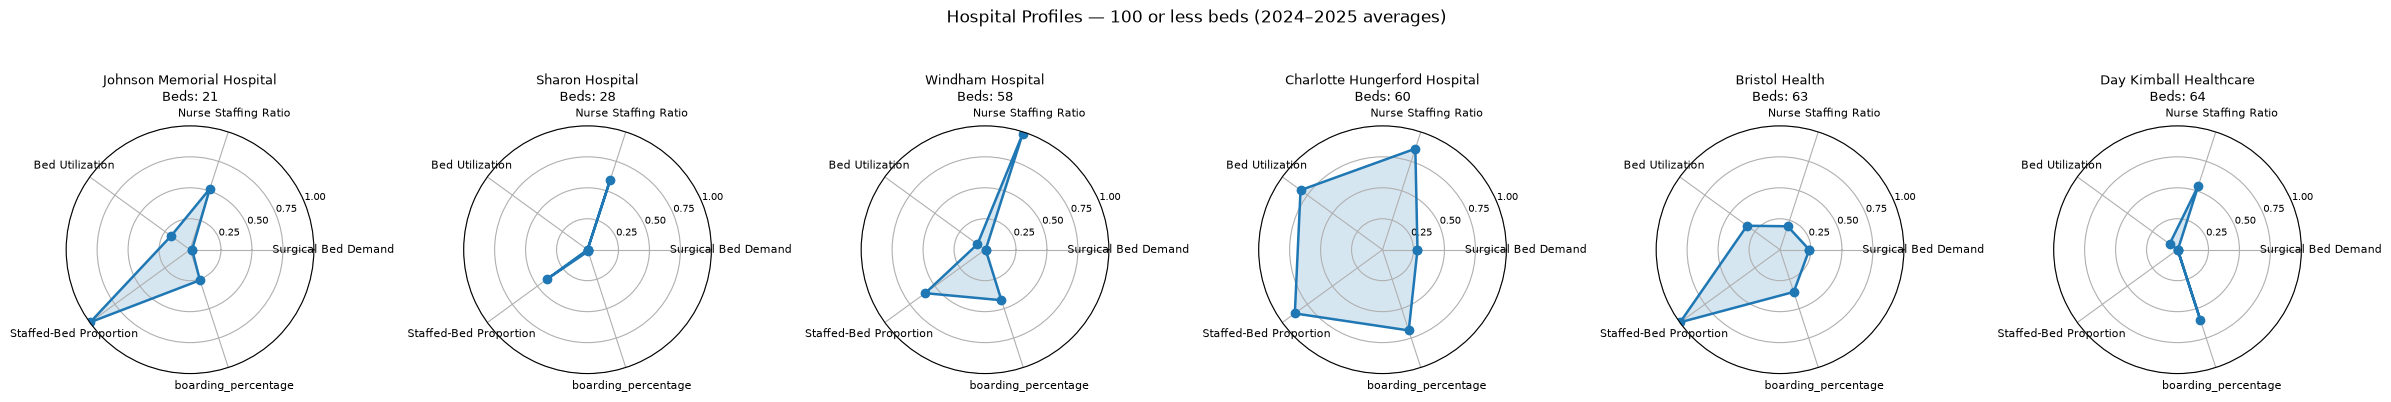

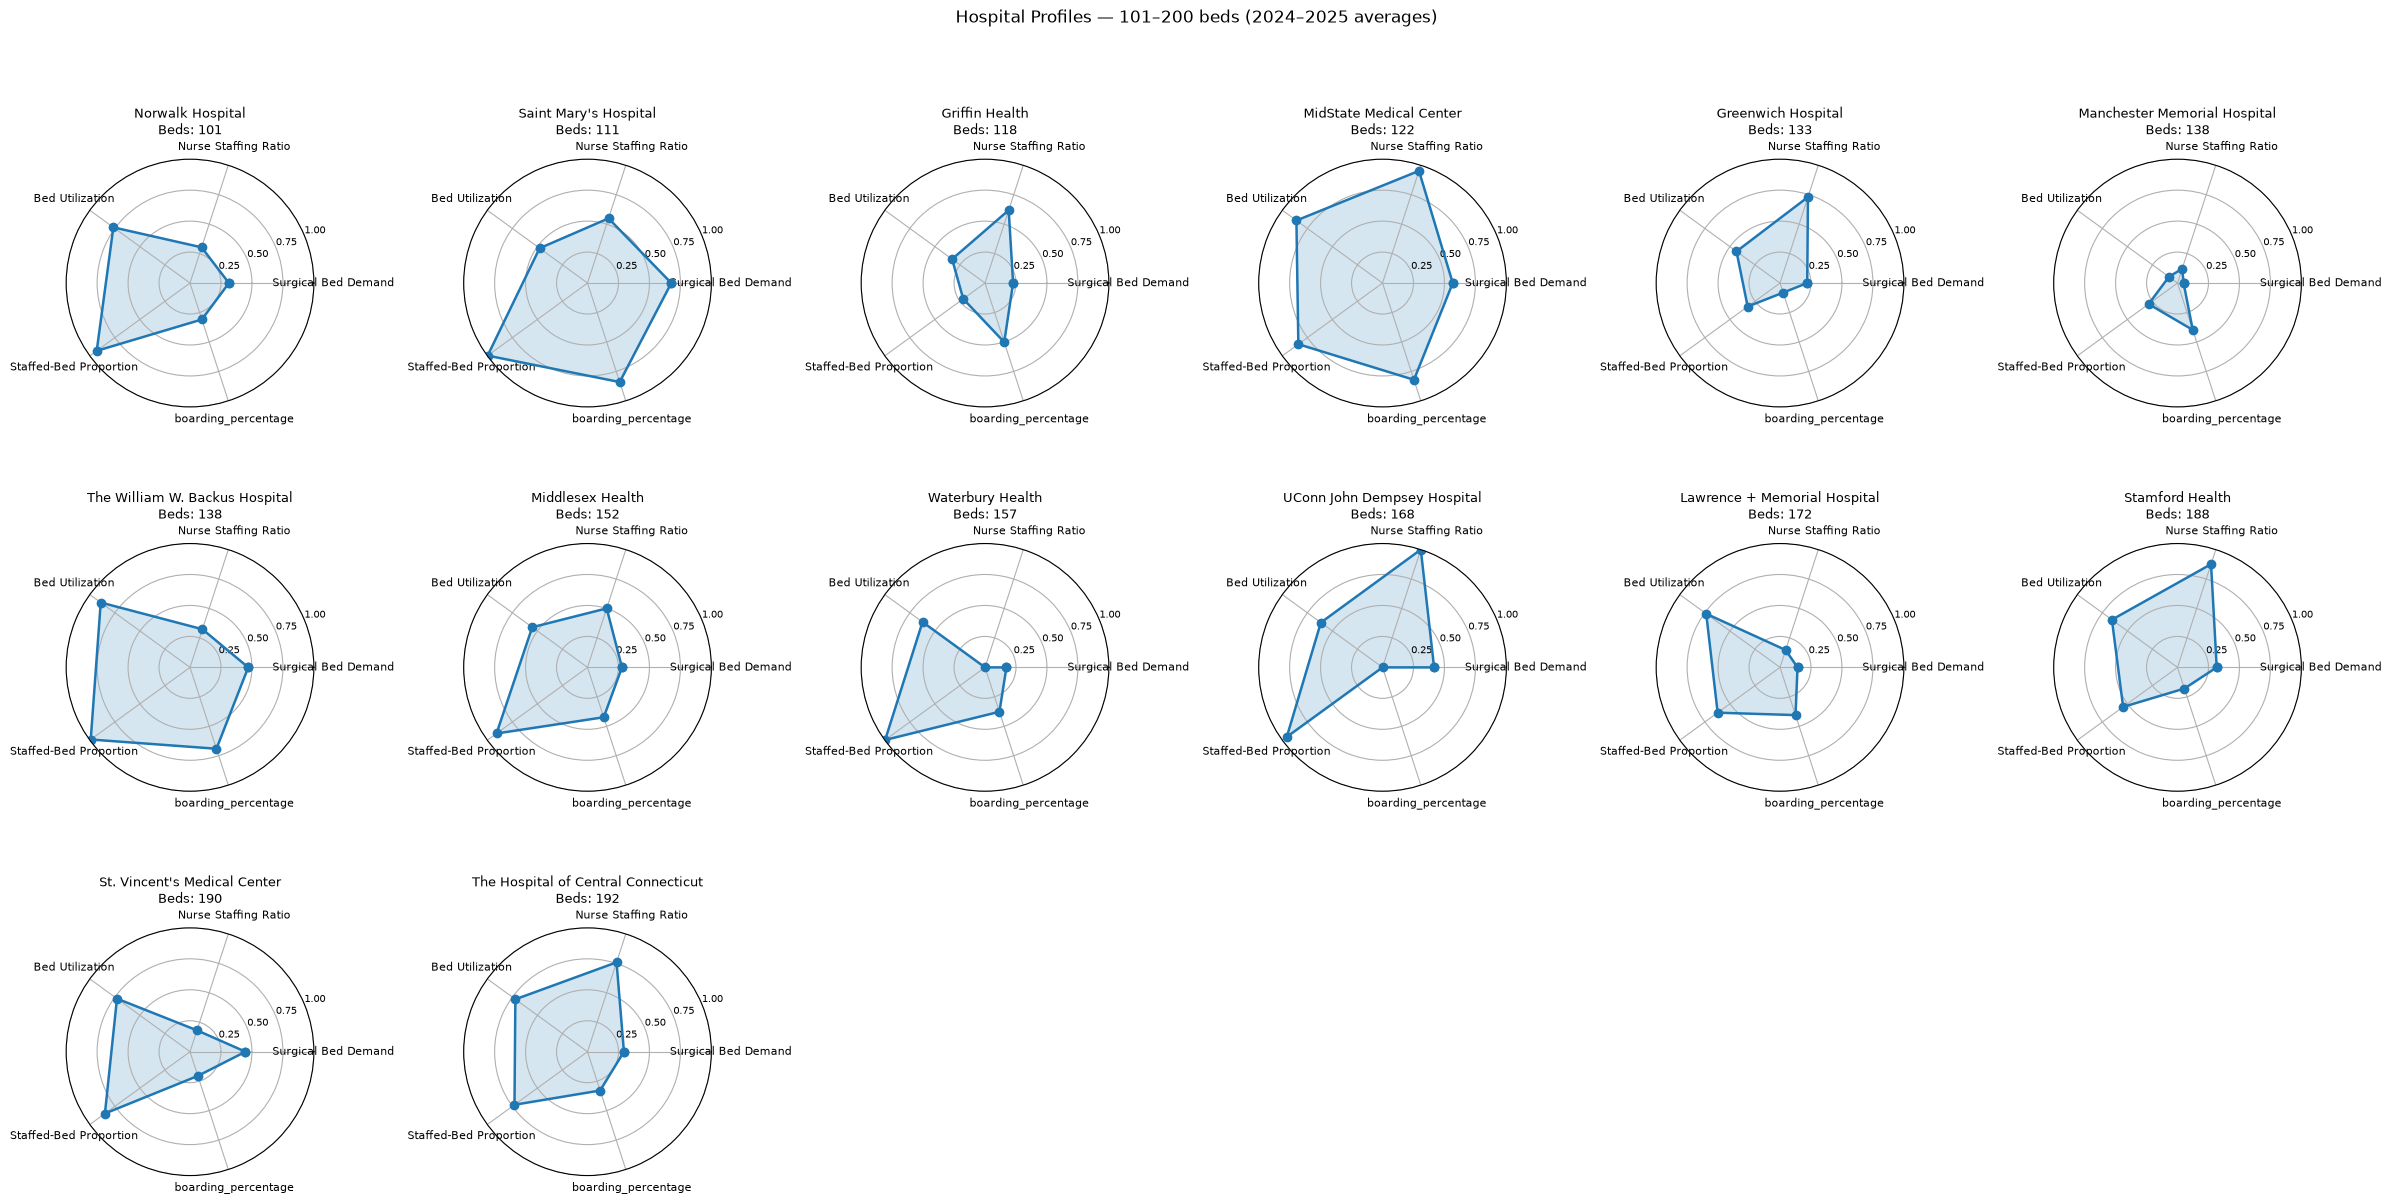

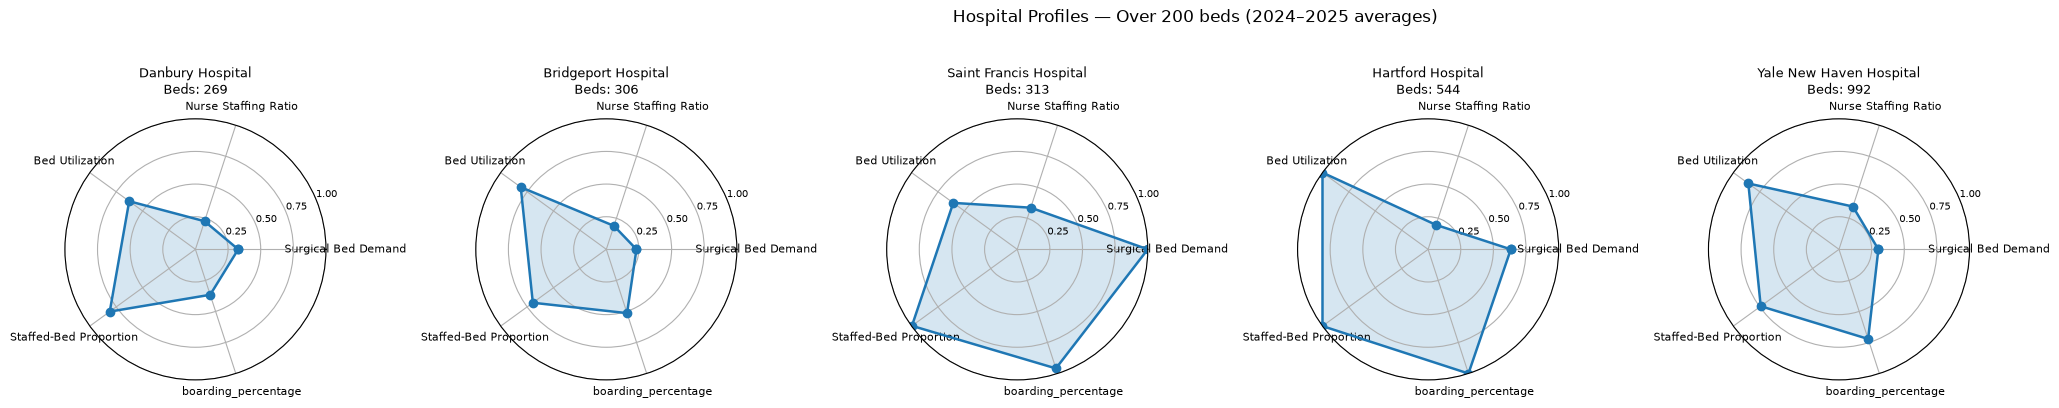

In [41]:
metrics = [
    'Surgical Bed Demand',
    'Nurse Staffing Ratio',
    'Bed Utilization',
    'Staffed-Bed Proportion',
    'boarding_percentage'
]

# Average each metric and bed count across years for each hospital.
hospital_data = (
    main_data.reset_index()
    .groupby('hospital_slug')
    .agg({
        **{metric: 'mean' for metric in metrics},
        'available_beds_medical_surgical': 'mean',
        'CCEP_name': 'first',
    })
    .rename(columns={'available_beds_medical_surgical': 'grouping_bed_count'})
)

# Min–max scale each metric across all hospitals.
metric_min = hospital_data[metrics].min()
metric_range = hospital_data[metrics].max() - metric_min
hospital_scaled = (hospital_data[metrics] - metric_min).div(metric_range.where(metric_range != 0, 1))

# Assign hospitals to non-overlapping bed-count groups.
hospital_data['bed_group'] = pd.cut(
    hospital_data['grouping_bed_count'],
    bins=[-np.inf, 100, 200, np.inf],
    labels=['100 or less', '101–200', 'Over 200'],
    right=True,
    ordered=True,
)

angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
closed_angles = angles + angles[:1]

output_dir = Path('./analysis_data/Processed Data')
output_dir.mkdir(parents=True, exist_ok=True)

for group_label in hospital_data['bed_group'].cat.categories:
    group_hospitals = hospital_data[hospital_data['bed_group'] == group_label].sort_values('grouping_bed_count', ascending=True)
    if group_hospitals.empty:
        continue

    ncols = 6
    nrows = int(np.ceil(len(group_hospitals) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(4 * ncols, 4 * nrows),
        subplot_kw={'polar': True},
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, (hospital_slug, row) in zip(axes, group_hospitals.iterrows()):
        values = hospital_scaled.loc[hospital_slug, metrics].tolist()
        ax.plot(closed_angles, values + values[:1], linewidth=1.8, marker='o')
        ax.fill(closed_angles, values + values[:1], alpha=0.18)
        ax.set_xticks(angles)
        ax.set_xticklabels(metrics, fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_yticklabels(['0.25', '0.50', '0.75', '1.00'], fontsize=7)
        ax.set_title(
            f"{row['CCEP_name']}\nBeds: {row['grouping_bed_count']:.0f}",
            fontsize=9,
            pad=18,
        )

    for ax in axes[len(group_hospitals):]:
        ax.set_visible(False)

    fig.suptitle(f'Hospital Profiles — {group_label} beds (2024–2025 averages)', y=1.02)
    fig.tight_layout()
    filename = str(group_label).lower().replace(' ', '_').replace('–', '-')
    fig.savefig(output_dir / f'spider_plots_{filename}_beds.png', dpi=300, bbox_inches='tight')
plt.show()